## Victor Zhang, Sebastien Sergile, Sam Young, Tamiru Workneh

## Lab
- You submit an .ipynb or .py that does two things:
    1. Determines an optimal price algorithmically (your code searches for and discovers an optimal price)
    2. Tracks the total number of consumers you have experimented with (at the optimum, each consumer has an expected profit of \$11.925)

- The optimal price is between 0 and 70: There is no reason to consider prices outside that range
- There are multiple prices that appear optimal, but only one is globally optimal

- Provide a 1-3 page write-up explaining your design, including tables and plots as necessary:
    1. A one-paragraph summary of the problem
    2. Two paragraphs about how your design handles uncertainty about changes in revenue and selects prices
    3. Two paragraphs about challenges you faced and how you resolved them
    4. One paragraph that summarizes your results. In particular, how many consumers did you experiment on, what were your revenues during the experiments, and what percentage of the optimal profit (\$11.925 per customer) did you capture?


## Issues to Consider

- How much data do you want to gather?
- Do you really want 90/95/99% confidence for setting prices?
- How do you combine brute force grid search?
- What is the minimum step size between prices you want to test?
- How should you adjust your sample size based on the information you are getting at a given price?
- If you cache experiments, can you gather data incrementally to constrain costs?

## Set Up Code:

In [40]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

rng = np.random.default_rng(100)

def purchase_probability(price):
    price = np.asarray(price, dtype=float)
    return (
        0.55 * np.exp(-np.logaddexp(0.0, (price - 13.9) / 0.8))
        + 0.30 * np.exp(-np.logaddexp(0.0, (price - 30.9) / 1.2))
        + 0.15 * np.exp(-np.logaddexp(0.0, (price - 58.4) / 1.8))
    )

def sales(price=14.0, rng=None, mean_customers=30):
    price = float(price)
    if not np.isfinite(price):
        raise ValueError("price must be finite")
    if price < 0:
        raise ValueError("price must be nonnegative")
    mean_customers = float(mean_customers)
    if not np.isfinite(mean_customers) or mean_customers < 0:
        raise ValueError("mean_customers must be finite and nonnegative")
    rng = np.random.default_rng(rng)
    customer_count = rng.poisson(mean_customers)
    probability = purchase_probability(price)
    return rng.binomial(1, probability, size=customer_count).astype(np.int8)

# First set of experiments:

- Perform 14 experiments: the first uses a price of \$5 and aims to experiment on 300 customers. Each subsequent experiment increases the price by \$5 on ~300 customers until we perform our upper experiment using a price of \$70
- We then calculate the total purchases, total revenue and revenue per customer for each experiment
- We can plot the revenue per customer vs price (aka each experiment) to get a visual sense of which price ranges performed the best (revenue wise)
- This first set of experiments is broad and not granular: we are looking for general trends and peaks to get a general sense of the optimal price range
- We will hone in a smaller range of prices to perform our second set of experiments using the data from this first set

In [41]:
# Prices to experiment with
prices = np.arange(5, 70, 5)

# Expected customers at each price
experiment_size = 300

results = []
total_customers = 0
total_revenue = 0

for price in prices:

    purchases = sales(
        price=price,
        mean_customers=experiment_size,
        rng=rng
    )

    customers = len(purchases)
    revenue = purchases.sum() * price
    revenue_per_customer = revenue / customers


    total_customers += customers
    total_revenue += revenue

    results.append({
        "price": price,
        "customers": customers,
        "revenue": revenue,
        "revenue_per_customer": revenue_per_customer,
        'purchases': purchases.sum()
    })

results_df = pd.DataFrame(results)

best_row = results_df.loc[
    results_df["revenue_per_customer"].idxmax()
]

print("Best price:", best_row["price"])
print("Estimated revenue/customer:",
      best_row["revenue_per_customer"])
print("Total customers experimented on:", total_customers)
print("Total experimental revenue:", total_revenue)
results_df

Best price: 30.0
Estimated revenue/customer: 10.808080808080808
Total customers experimented on: 3882
Total experimental revenue: 25385


,price,customers,revenue,revenue_per_customer,purchases
0,5,319,1595,5.000000,319
1,10,324,3230,9.969136,323
2,15,305,2490,8.163934,166
3,20,292,2680,9.178082,134
4,25,276,2500,9.057971,100
5,30,297,3210,10.808081,107
6,35,302,1610,5.331126,46
7,40,279,1560,5.591398,39
8,45,269,1575,5.855019,35
9,50,277,1500,5.415162,30


# Experiment results plot:

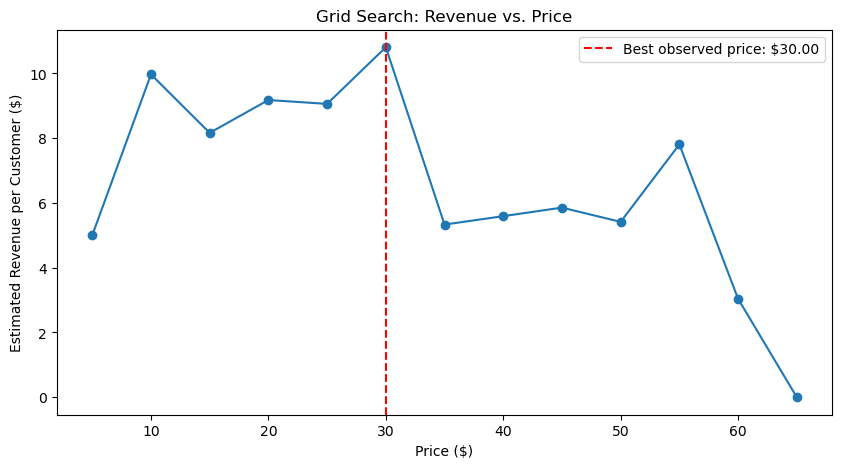

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    results_df["price"],
    results_df["revenue_per_customer"],
    marker="o"
)

plt.axvline(
    best_row["price"],
    color="red",
    linestyle="--",
    label=f'Best observed price: \${best_row["price"]:.2f}'
)

plt.xlabel("Price (\$)")
plt.ylabel("Estimated Revenue per Customer (\$)")
plt.title("Grid Search: Revenue vs. Price")
plt.legend()
plt.show()

- There are multiple peaks throughout the price range \$0-70 but the most promising and consistent range seems to be prices from \$20-\$30. There is a promising peak at \$10, but the revenue per customer drops off more considerably at the \$5 and \$15 price. On the other hand, prices 20, 25 and 30 all performed well, so lets isolate our set of second experiments to this range and look at prices at each \$1 interval in between. Also, let's increase the customers per experiment and aim for 500 at each interval to get more robust results.

C:\Users\Sebastien\AppData\Local\Temp\ipykernel_8792\652920361.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


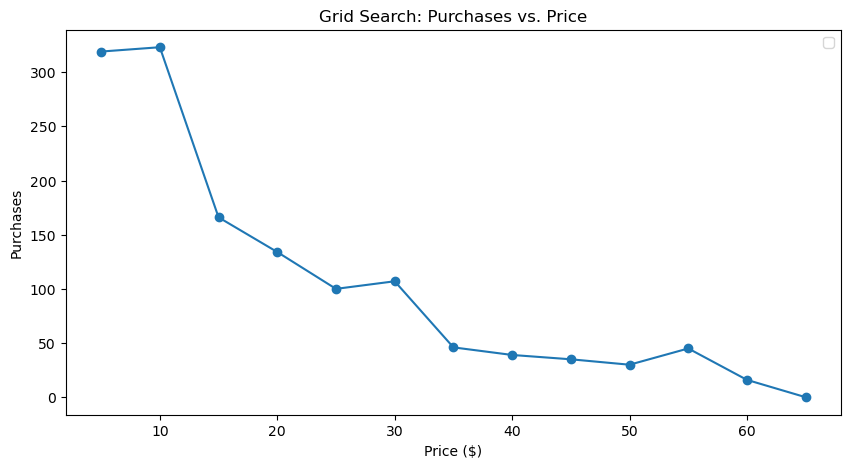

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    results_df["price"],
    results_df["purchases"],
    marker="o"
)


plt.xlabel("Price (\$)")
plt.ylabel("Purchases")
plt.title("Grid Search: Purchases vs. Price")
plt.legend()
plt.show()

## Percentage of optimal revenue captured from our first set of experiments:

In [ ]:
optimal_revenue = total_customers * 11.925

percentage_captured = (
    total_revenue / optimal_revenue
) * 100

print(f"Total customers: {total_customers}")
print(f"Total experimental revenue: \${total_revenue:.2f}")
print(f"Optimal benchmark revenue: \${optimal_revenue:.2f}")
print(f"Percentage of optimal revenue captured: {percentage_captured:.2f}%")

Total customers: 3882
Total experimental revenue: $25385.00
Optimal benchmark revenue: $46292.85
Percentage of optimal revenue captured: 54.84%


**An aside:**

- As seen above, purchases generally go down as price increases (which makes sense). But there are several instances where this is not the case. This displays some of the randomness associated with purchases and the noise involved in our experiments

# Second set of experiments:

From our first set of experiments, the price that gave us the highest revenue per customer was \$30. Now we will perform a more granular set of experiments on a range of prices from \$20 to \$30, incrementing by \$1. This time we are setting our experiment size to 500. For the first set of experiments it was 300.

In [45]:
# Prices to experiment with
prices = np.arange(20, 30, 1)

# Expected customers at each price
experiment_size = 500

results = []
total_customers = 0
total_revenue = 0

for price in prices:

    purchases = sales(
        price=price,
        mean_customers=experiment_size,
        rng=rng
    )

    customers = len(purchases)
    revenue = purchases.sum() * price
    revenue_per_customer = revenue / customers

    total_customers += customers
    total_revenue += revenue

    results.append({
        "price": price,
        "customers": customers,
        "revenue": revenue,
        "revenue_per_customer": revenue_per_customer
    })

results_df = pd.DataFrame(results)

best_row = results_df.loc[
    results_df["revenue_per_customer"].idxmax()
]

print("Best price:", best_row["price"])
print("Estimated revenue/customer:",
      best_row["revenue_per_customer"])
print("Total customers experimented on:", total_customers)
print("Total experimental revenue:", total_revenue)
results_df

Best price: 27.0
Estimated revenue/customer: 11.767820773930753
Total customers experimented on: 4973
Total experimental revenue: 53351


,price,customers,revenue,revenue_per_customer
0,20,492,4820,9.796748
1,21,466,4263,9.148069
2,22,513,5346,10.421053
3,23,504,4853,9.628968
4,24,503,5472,10.878728
5,25,517,5750,11.121857
6,26,497,5798,11.665996
7,27,491,5778,11.767821
8,28,509,5964,11.717092
9,29,481,5307,11.033264


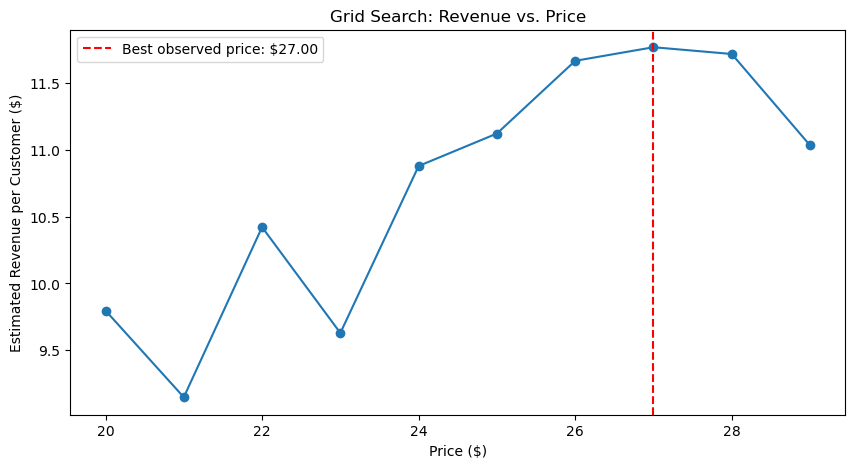

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    results_df["price"],
    results_df["revenue_per_customer"],
    marker="o"
)

plt.axvline(
    best_row["price"],
    color="red",
    linestyle="--",
    label=f'Best observed price: \${best_row["price"]:.2f}'
)

plt.xlabel("Price (\$)")
plt.ylabel("Estimated Revenue per Customer (\$)")
plt.title("Grid Search: Revenue vs. Price")
plt.legend()
plt.show()

- \$27 had the highest revenue per customer in this stage, but \$28 was close behind, so we cannot yet say which is truly better.
- We have already experimented on 9,000 customers and have earned x total revenue in our two sets of experiments. Knowing that the optimal rev per customer is ~11.925, we have only captured X% of the total optimal revenue in our experiments

## Percentage of optimal revenue captured from our second set of experiments:

In [ ]:
optimal_revenue = total_customers * 11.925

percentage_captured = (
    total_revenue / optimal_revenue
) * 100

print(f"Total customers: {total_customers}")
print(f"Total experimental revenue: \${total_revenue:.2f}")
print(f"Optimal benchmark revenue: \${optimal_revenue:.2f}")
print(f"Percentage of optimal revenue captured: {percentage_captured:.2f}%")

Total customers: 4973
Total experimental revenue: $53351.00
Optimal benchmark revenue: $59303.03
Percentage of optimal revenue captured: 89.96%


# Confidence Interval code

In [48]:
# Stage 3: Calculate confidence intervals

confidence_results = []

for price in prices:

    purchases = sales(
        price=price,
        mean_customers=1000,
        rng=rng
    )

    # Revenue generated by each customer
    customer_revenue = purchases * price

    # Average revenue per customer
    mean_revenue = customer_revenue.mean()

    # Standard error
    se = customer_revenue.std(ddof=1) / np.sqrt(len(customer_revenue))

    # 90% confidence interval
    ci_lower = mean_revenue - 1.645 * se
    ci_upper = mean_revenue + 1.645 * se

    confidence_results.append({
        "price": price,
        "mean_revenue": mean_revenue,
        "se": se,
        "ci_lower": ci_lower,
        "ci_upper": ci_upper,
        "customers": len(customer_revenue)
    })

confidence_df = pd.DataFrame(confidence_results)

## Confidence intervals for mean revenue of our top two best prices:

In [49]:
# Find the two prices with highest estimated revenue
top_two = confidence_df.nlargest(2, "mean_revenue")
top_two

,price,mean_revenue,se,ci_lower,ci_upper,customers
8,28,12.652482,0.443781,11.922463,13.382502,987
7,27,11.784236,0.420512,11.092494,12.475979,1015


## Confidence interval for the difference in revenue between our top two prices:

In [50]:
price_A = top_two.iloc[0]
price_B = top_two.iloc[1]

# Difference in estimated mean revenue
difference = (
    price_A["mean_revenue"] -
    price_B["mean_revenue"]
)

# Standard error of the difference
se_difference = np.sqrt(
    price_A["se"]**2 +
    price_B["se"]**2
)

# 90% confidence interval
ci_lower = difference - 1.645 * se_difference
ci_upper = difference + 1.645 * se_difference

print("Price A:", price_A["price"])
print("Price B:", price_B["price"])

print("Difference in revenue:", difference)
print("90% CI:", (ci_lower, ci_upper))

Price A: 28.0
Price B: 27.0
Difference in revenue: 0.8682458163015756
90% CI: (-0.1374559857088904, 1.8739476183120416)


## Final independent comparison and confidence interval:

Our two best prices are \$27 and \$28. Now we are doing one last set of two experiments, one for each of the top two best prices. This time our experiment size is 5000.

In [ ]:
# Final independent comparison

p_A = float(price_A["price"])
p_B = float(price_B["price"])

final_size = 5000

revenue_A = sales(
    p_A,
    mean_customers=final_size,
    rng=rng
) * p_A

revenue_B = sales(
    p_B,
    mean_customers=final_size,
    rng=rng
) * p_B

# Update experiment totals
total_customers = len(revenue_A) + len(revenue_B)
total_revenue = revenue_A.sum() + revenue_B.sum()

# Difference in mean revenue
delta = revenue_A.mean() - revenue_B.mean()

# Standard error
se = np.sqrt(
    revenue_A.var(ddof=1) / len(revenue_A) +
    revenue_B.var(ddof=1) / len(revenue_B)
)

# Confidence interval
lower = delta - 1.645 * se
upper = delta + 1.645 * se

print(f"Difference: {delta:.3f}")
print(f"90% CI: ({lower:.3f}, {upper:.3f})")

if lower > 0:
    best_price = p_A
elif upper < 0:
    best_price = p_B
else:
    best_price = (
        p_A if revenue_A.mean() >= revenue_B.mean()
        else p_B
    )
    print("No statistically clear winner; selecting higher observed mean.")

print(f"Selected price: \${best_price:.2f}")

Difference: -0.107
90% CI: (-0.553, 0.340)
No statistically clear winner; selecting higher observed mean.
Selected price: $27.00


## Now we will calculate the percentage of the optimal revenue that our two final experiments captured.

Optimal revenue is the revenue we would have if we charge the optimal price.

In [ ]:
# Include customers and revenue from every experiment
# before calculating these metrics.

optimal_revenue = total_customers * 11.925

percentage_captured = (
    total_revenue / optimal_revenue
) * 100

print(f"Total customers: {total_customers}")
print(f"Total experimental revenue: \${total_revenue:.2f}")
print(f"Optimal benchmark revenue: \${optimal_revenue:.2f}")
print(f"Percentage captured: {percentage_captured:.2f}%")

Total customers: 10099
Total experimental revenue: $122076.00
Optimal benchmark revenue: $120430.58
Percentage captured: 101.37%


1. A seller must choose one price between \$0 and \$70 without knowing how likely customers are to buy at each price. Every price experiment returns only a random number of customers who either buy or don’t, so any estimate of revenue per customer is noisy. Each customer in an experiment is also a real customer who pays a possibly poor price, so experimenting has a cost. The goal is to find the revenue-maximizing price while giving up as little revenue as possible along the way, measured against the benchmark of \$11.925 expected profit per customer at the optimum. The difficulty is that demand has several local peaks, so a price that looks good in one region may not be the global best.

2. The design narrows the price range in stages and uses larger samples as the candidates get closer together. Stage 1 is a coarse grid from \$5 to \$65 in \$5 increments, with about 300 customers per price. It's cheap and shows which regions earn the most per customer. The best region was \$20–\$30, so Stage 2 tested every dollar from \$20 to \$29 with about 500 customers each. Larger samples are used here because neighboring prices differ by small amounts that are hard to detect through noise. Since each customer either pays the full price or nothing, revenue per customer is highly variable without a large sample size.

To quantify the uncertainty, Stage 3 ran about 1,000 customers at each price from \$20 to \$29 and computed 90% confidence intervals (mean ± 1.645 standard errors) for revenue per customer. We chose 90% instead of 95% or 99% because tighter confidence needs more customers, and each costs revenue. The two best prices, \$28 and \$27, could not be separated, as the 90% interval for their difference (−0.14 to 1.87) included zero. Stage 4 ran a fresh, independent 5,000-customer experiment at each finalist and built an interval for the difference. The rule was to pick a price only if the interval for the difference excluded zero, and otherwise to pick the one with the higher observed mean. The result was a difference of −0.107 in the means with a 90% interval of (−0.553, 0.340), so no clear winner emerged and we selected \$27.

3. The first challenge was noise. Purchase counts did not always fall as price rose, and revenue per customer at neighboring prices differed by amounts comparable to random variation, so reading the best price off a single experiment was unreliable. The coarse grid that skipped by \$5 was a related concern because it can skip narrow peaks, so We used it only to choose a region to examine and confirmed the finalists with larger samples. In Stage 3, \$28 appeared to earn \$12.65 per customer, which is above the \$11.925 maximum possible expected profit. Rather than trusting that value, We re-tested the finalists on new, independent data in Stage 4, which showed that \$27 had the higher mean in that experiment.

The second challenge was deciding how much data to gether. Small samples were cheap but uncertain, while large samples were more certain but costly. We decided to use small samples to explore the data to get a better idea of what ranges would be optimal, and from there increased the sample size to determine the top 2 candidates. Once we found those we increased sample size again to determine if one price was better than another. Another challenge was interpreting the percentage of optimal figures. The benchmark of \$11.925 is an expected value, so any single stage can land above or below it by chance. The final stage’s figure of 101.37% exceeds the benchmark for that reason: it covered only \$27 and \$28, whose true expected revenue is close to optimal, and it happened to come out about 1.5% higher than the expected optimal revenue. We treated this as noise rather than as evidence of beating the optimum.

4. We experimented on 28,888 customers in total and earned \$308,882 during the experiments. The optimal benchmark for that many customers is \$344,489, so we captured 89.66% of the optimal profit throughout the experiment.

| Stage                                   | Customers |  Revenue | % of optimal |
|:----------------------------------------|----------:|---------:|-------------:|
| 1: Coarse grid                          |     3,882 |  \$25,385 |       54.84% |
| 2: Fine grid                            |     4,973 |  \$53,351 |       89.96% |
| 3: Confidence-interval experiments*     |     9,934 | \$108,070 |       91.23% |
| 4: Final head-to-head                   |    10,099 | \$122,076 |      101.37% |
| **Total**                               |**28,888** |**\$308,882**|   **89.66%** |


Stage 1 was the most costly because we deliberately tested on poor prices, and as the range of values that we were experimenting on decreased, we got closer to the optimal benchmark.